<a href="https://colab.research.google.com/github/anakhasj2002-code/Assignments/blob/main/Data%20Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
# Load the taxis dataset
df = sns.load_dataset ("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
# Check missing values
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [ ]:
# Fill missing categorical values using mode
for col in ['payment','pickup_zone','dropoff_zone','pickup_borough','dropoff_borough']:
    df[col].fillna(df[col].mode()[0])
# Check missing values again
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


In [ ]:
# Fill missing categorical values using mode
for col in ['pickup_zone','dropoff_zone','pickup_borough','dropoff_borough']:
    df[col].fillna(df[col].mode()[0])
# Check missing values again
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


In [ ]:
# Handle missing values
cols=['payment','pickup_zone','dropoff_zone','pickup_borough','dropoff_borough']
for col in cols:
    df[col].fillna(df[col].mode()[0],inplace=True)
# Check missing values again
df.isnull().sum()

/tmp/ipykernel_3301/80835416.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0],inplace=True)


,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


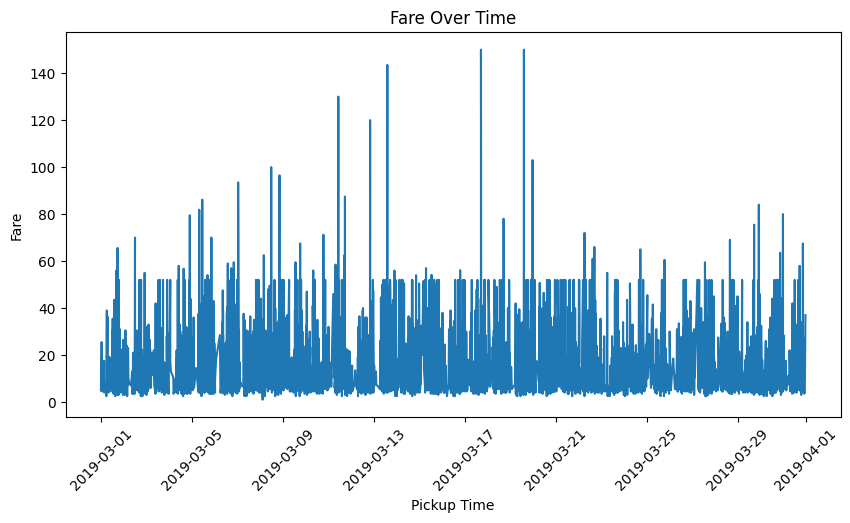

In [ ]:
# Convert pickup column to datetime
df['pickup'] = pd.to_datetime(df['pickup'])

# Sort data by pickup time
df=df.sort_values('pickup')

# Create Line Chart
plt.figure(figsize=(10,5))
plt.plot(df['pickup'], df['fare'])

plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.title('Fare Over Time')
plt.xticks(rotation=45)
plt.show()

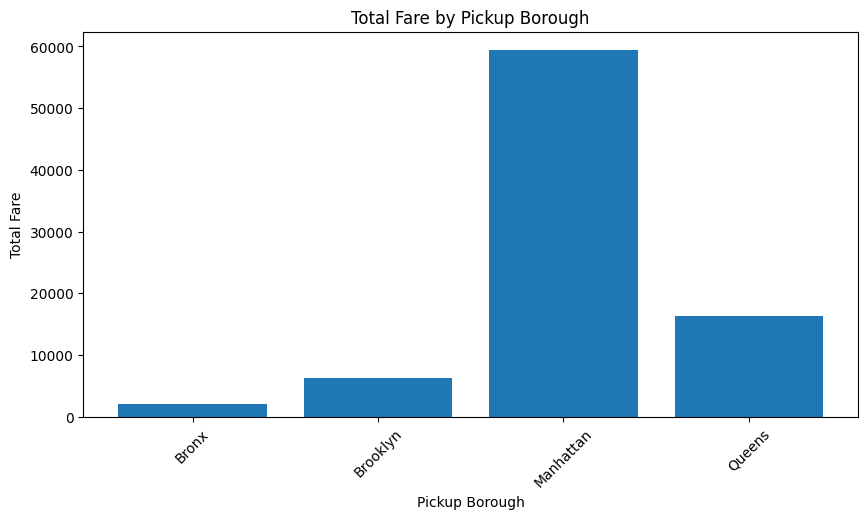

In [ ]:
# Group data by pickup_borough and calculate total fare
borough_fare = df.groupby('pickup_borough')['fare'].sum()

# Create Bar Chart
plt.figure(figsize=(10,5))
plt.bar(borough_fare.index, borough_fare.values)

plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.title('Total Fare by Pickup Borough')
plt.xticks(rotation=45)
plt.show()

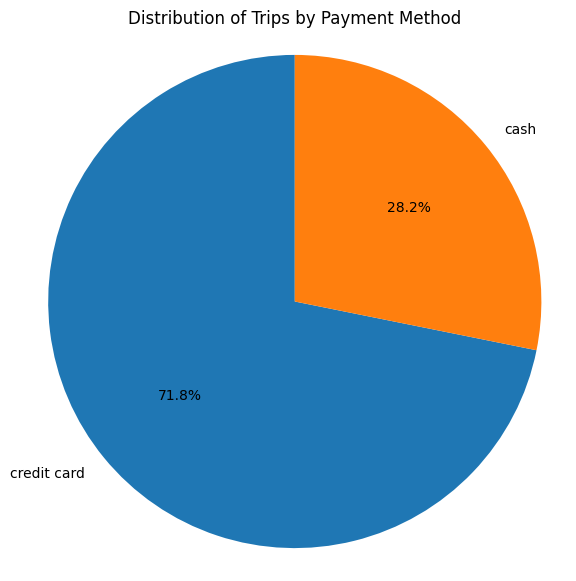

In [ ]:
# Count trips by payment method
payment_counts = df['payment'].value_counts()

# Create Pie Chart
plt.figure(figsize=(7,7))
plt.pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%',startangle=90)

plt.axis('equal')

plt.title('Distribution of Trips by Payment Method')
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

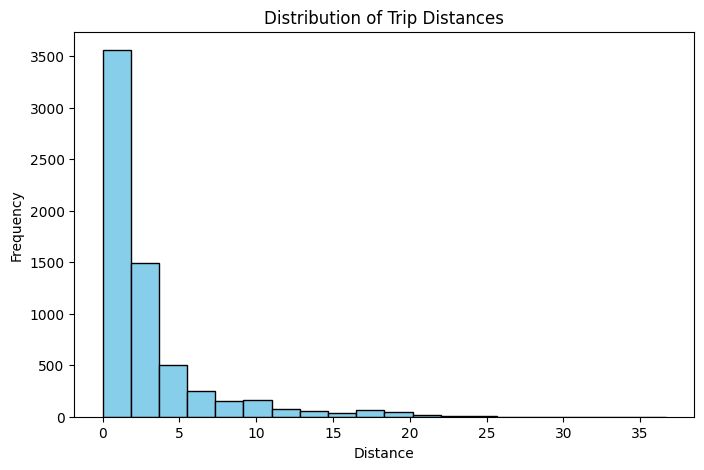

In [ ]:
# Create Histogram for Distance
plt.figure(figsize=(8,5))
plt.hist(df['distance'], bins=20, color='skyblue', edgecolor='black')

plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.title('Distribution of Trip Distances')
plt.show

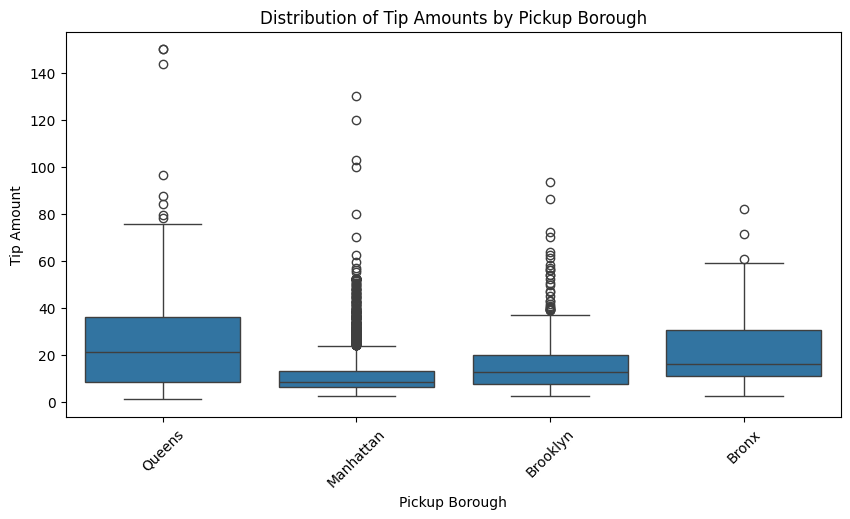

In [ ]:
# Create Box Plot
plt.figure(figsize=(10,5))
sns.boxplot(x='pickup_borough', y='fare', data=df)

plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.title('Distribution of Tip Amounts by Pickup Borough')
plt.xticks(rotation=45)
plt.show()

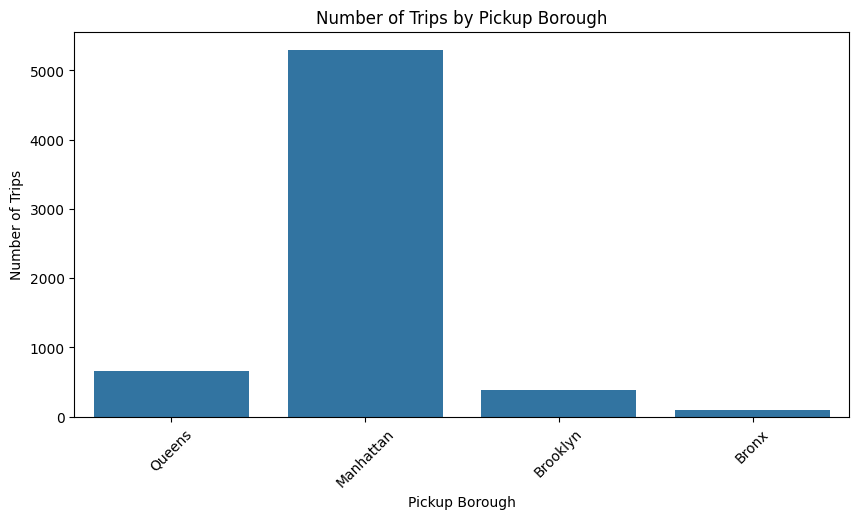

In [ ]:
# Count Plot of Pickup Borough
plt.figure(figsize=(10,5))
sns.countplot(x='pickup_borough', data=df)

plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.title('Number of Trips by Pickup Borough')
plt.xticks(rotation=45)
plt.show()

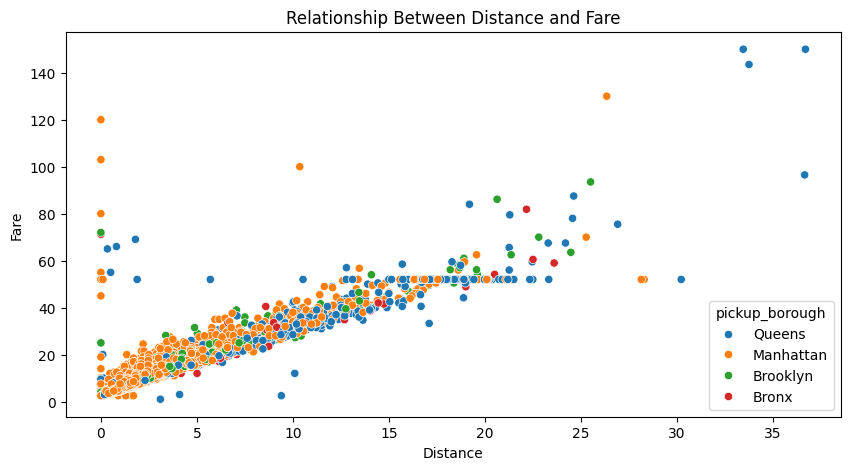

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(
    x='distance',
    y='fare',
    hue='pickup_borough',
    data=df
)

plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Relationship Between Distance and Fare')
plt.show()


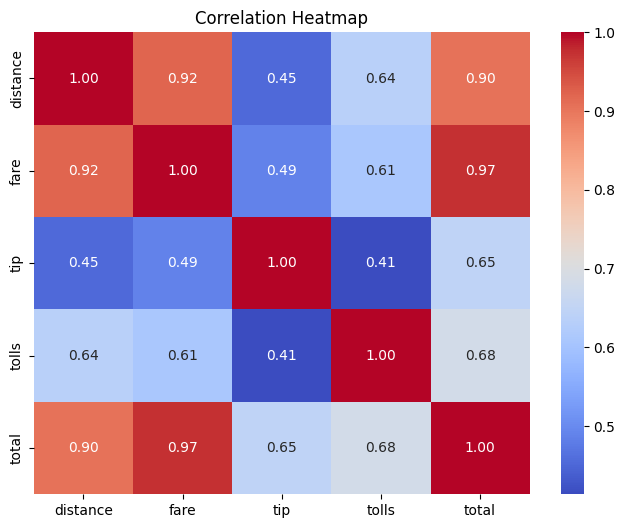

In [ ]:
# Select numerical Columns
numeric_df=df[['distance','fare','tip','tolls','total']]

# Create correlation matrix
correlation= numeric_df.corr()

# Plot Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()


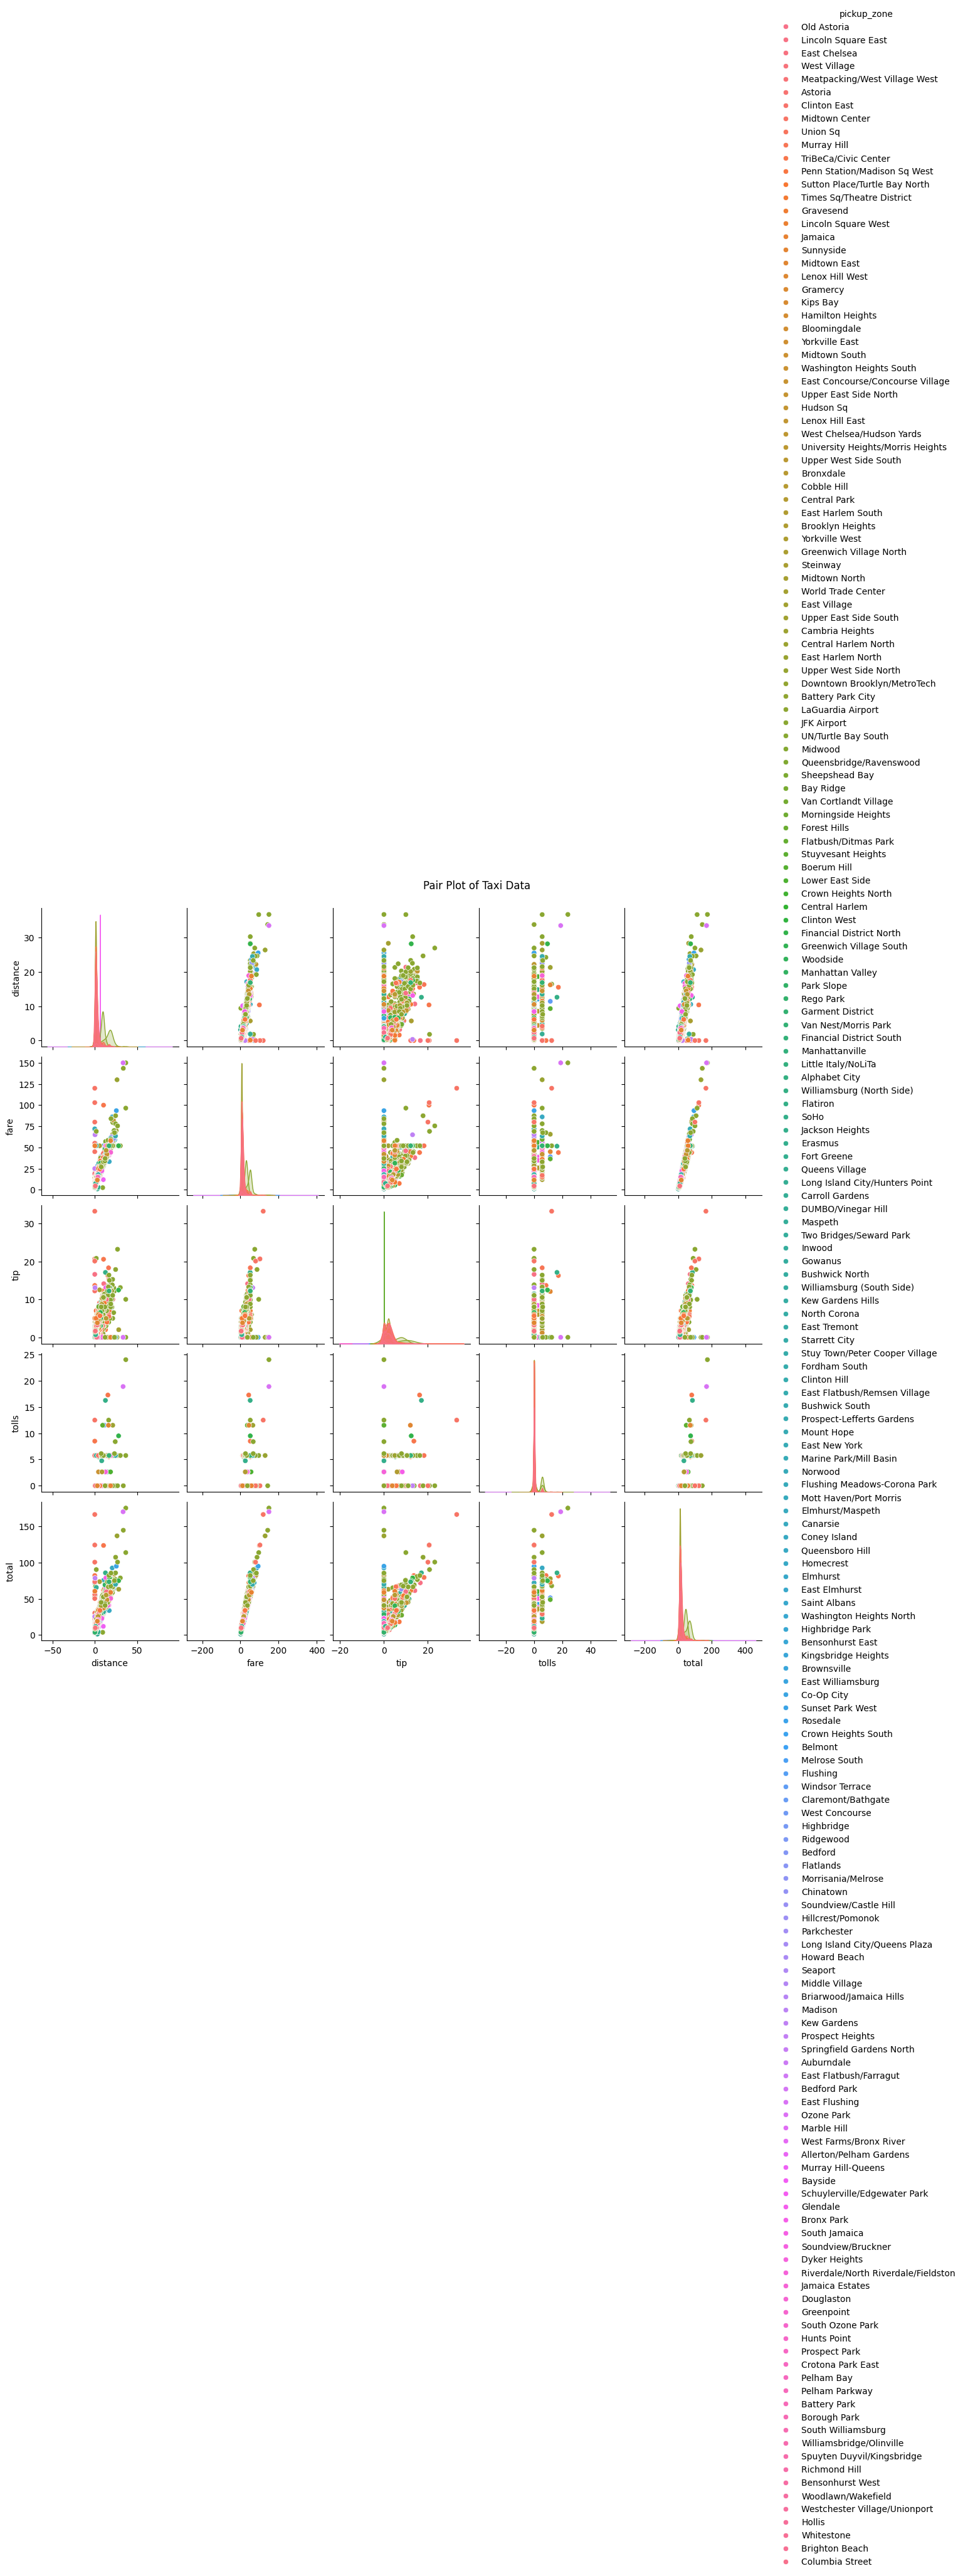

In [ ]:
# Create Pair Plot
sns.pairplot(df[['distance','fare','tip','tolls','total','pickup_zone']],
             hue='pickup_zone'
)
plt.suptitle('Pair Plot of Taxi Data',y=1.02)
plt.show()

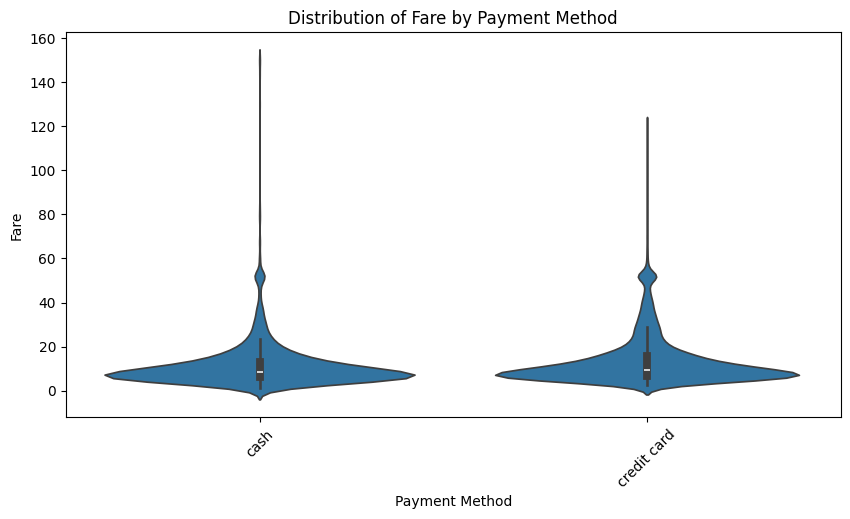

In [ ]:
# Create Violin Plot
plt.figure(figsize=(10,5))
sns.violinplot(x='payment', y='fare', data=df)

plt.xlabel('Payment Method')
plt.ylabel('Fare')
plt.title('Distribution of Fare by Payment Method')
plt.xticks(rotation=45)
plt.show()